<a href="https://colab.research.google.com/github/joem20/Planning-Europe/blob/main/Graph_Construction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

# Load frozen Dataset v1 directly from GitHub
url = "https://raw.githubusercontent.com/joem20/Planning-Europe/dataset-v1/routes_dataset_v1.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)

display(df.head())

Dataset loaded successfully!
Rows and columns: (27, 14)


,link_id,from_city,to_city,mode,operator,service,duration_min,time_hours,price_original,currency_original,price_gbp,date_checked,source_url,notes
0,L01,London,Paris,rail,Eurostar,Eurostar,140,2.333,58.0,GBP,58.0,2026-11-05,https://www.eurostar.com/search/uk-en?adult=1&...,The fare is a promotional price. All fares car...
1,L02,London,Brussels,rail,Eurostar,Eurostar,124,2.067,120.0,GBP,120.0,2026-11-05,https://www.eurostar.com/search/uk-en?adult=1&...,Eurostar 09:01 London St Pancras to Brussels M...
2,L03,London,Amsterdam,rail,Eurostar,Eurostar,244,4.067,95.0,GBP,95.0,2026-11-05,https://www.eurostar.com/search/uk-en?adult=1&...,Eurostar 08:16 London St Pancras to Amsterdam ...
3,L04,Paris,Brussels,rail,Eurostar,Eurostar,84,1.400,38.5,GBP,38.5,2026-11-05,https://www.eurostar.com/search/uk-en?adult=1&...,Eurostar 08:53 Paris Nord to Brussels Midi 10:...
4,L05,Paris,Amsterdam,rail,Eurostar,Eurostar,209,3.483,35.5,GBP,35.5,2026-11-05,https://www.eurostar.com/search/uk-en?adult=1&...,Eurostar 12:21 Paris Nord to Amsterdam Centraa...


In [9]:
print("NetworkX version:", nx.__version__)

NetworkX version: 3.7


In [ ]:
# Dataset structure and information

print("DATASET INFORMATION")
print("-------------------")

print("Number of records:", len(df))
print("Number of columns:", len(df.columns))

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nDataset information:")
df.info()

DATASET INFORMATION
-------------------
Number of records: 27
Number of columns: 14

Column names:
['link_id', 'from_city', 'to_city', 'mode', 'operator', 'service', 'duration_min', 'time_hours', 'price_original', 'currency_original', 'price_gbp', 'date_checked', 'source_url', 'notes']

Data types:
link_id               object
from_city             object
to_city               object
mode                  object
operator              object
service               object
duration_min           int64
time_hours           float64
price_original       float64
currency_original     object
price_gbp            float64
date_checked          object
source_url            object
notes                 object
dtype: object

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27 entries, 0 to 26
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   link_id            27 non-null     object 
 1   from_c

In [ ]:
# Data quality checks

print("MISSING VALUES")
print("----------------")
print(df.isnull().sum())

print("\nTOTAL MISSING VALUES:")
print(df.isnull().sum().sum())

print("\nDUPLICATE RECORDS")
print("------------------")
print("Exact duplicates:", df.duplicated().sum())

print("\nDUPLICATE LINK IDs")
print("-------------------")
print("Duplicate IDs:", df['link_id'].duplicated().sum())

MISSING VALUES
----------------
link_id              0
from_city            0
to_city              0
mode                 0
operator             0
service              0
duration_min         0
time_hours           0
price_original       0
currency_original    0
price_gbp            0
date_checked         0
source_url           0
notes                0
dtype: int64

TOTAL MISSING VALUES:
0

DUPLICATE RECORDS
------------------
Exact duplicates: 0

DUPLICATE LINK IDs
-------------------
Duplicate IDs: 0


TRANSPORT MODE DISTRIBUTION
----------------------------
mode
rail     19
coach     8
Name: count, dtype: int64


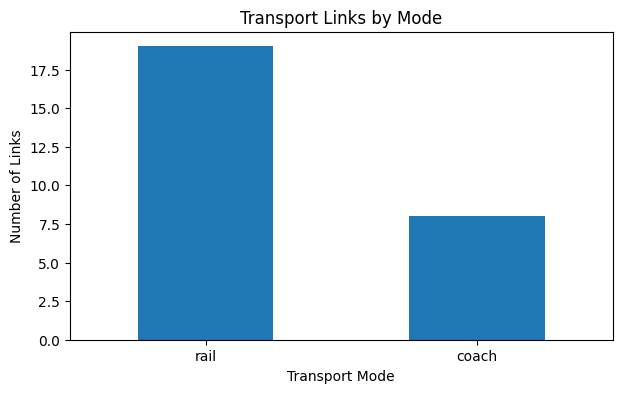

In [ ]:
# Transport mode distribution

print("TRANSPORT MODE DISTRIBUTION")
print("----------------------------")

mode_counts = df['mode'].value_counts()

print(mode_counts)

# Visualisation
mode_counts.plot(kind='bar', figsize=(7, 4))

plt.title('Transport Links by Mode')
plt.xlabel('Transport Mode')
plt.ylabel('Number of Links')
plt.xticks(rotation=0)
plt.show()

TRANSPORT LINKS BY OPERATOR
----------------------------
operator
FlixBus               8
Eurostar              7
Deutsche Bahn         6
FlixTrain             2
SNCF Voyageurs/SBB    1
OUIGO                 1
SBB/Trenitalia        1
Trenitalia            1
Name: count, dtype: int64


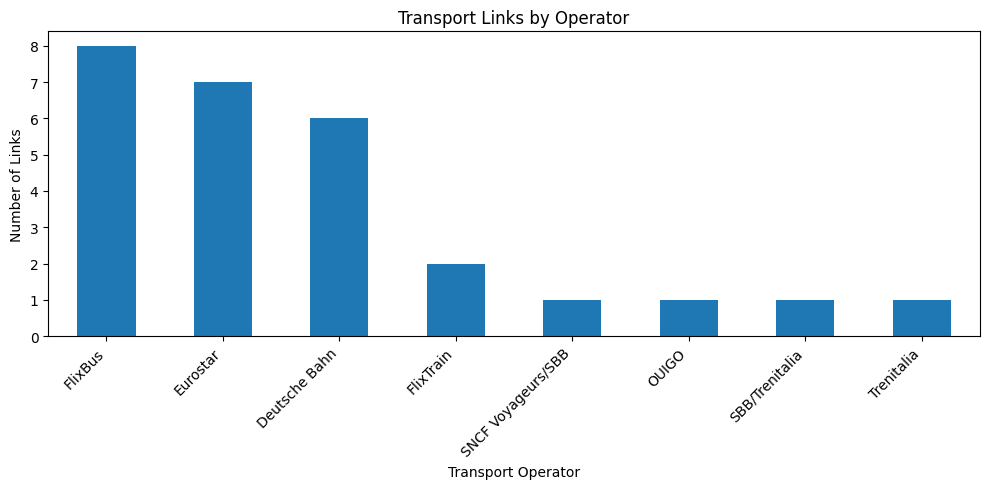

In [ ]:
# Operator distribution

print("TRANSPORT LINKS BY OPERATOR")
print("----------------------------")

operator_counts = df['operator'].value_counts()

print(operator_counts)

# Create bar chart
operator_counts.plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title('Transport Links by Operator')
plt.xlabel('Transport Operator')
plt.ylabel('Number of Links')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [ ]:
# Descriptive statistics

print("JOURNEY TIME STATISTICS")
print("-----------------------")
print(df['duration_min'].describe())

print("\nGBP PRICE STATISTICS")
print("-------------------")
print(df['price_gbp'].describe())

print("\nAVERAGE PRICE BY MODE")
print("---------------------")
print(df.groupby('mode')['price_gbp'].mean())

print("\nAVERAGE JOURNEY TIME BY MODE")
print("----------------------------")
print(df.groupby('mode')['duration_min'].mean())

JOURNEY TIME STATISTICS
-----------------------
count     27.00000
mean     267.37037
std      161.86275
min       69.00000
25%      132.00000
50%      240.00000
75%      372.50000
max      690.00000
Name: duration_min, dtype: float64

GBP PRICE STATISTICS
-------------------
count     27.000000
mean      39.135185
std       27.039193
min        8.490000
25%       21.170000
50%       30.850000
75%       51.600000
max      120.000000
Name: price_gbp, dtype: float64

AVERAGE PRICE BY MODE
---------------------
mode
coach    22.490000
rail     46.143684
Name: price_gbp, dtype: float64

AVERAGE JOURNEY TIME BY MODE
----------------------------
mode
coach    426.250000
rail     200.473684
Name: duration_min, dtype: float64


In [ ]:
# Identify routes with multiple transport options

analysis_df = df.copy()

# Treat routes as undirected
analysis_df['route'] = analysis_df.apply(
    lambda row: ' - '.join(
        sorted([row['from_city'], row['to_city']])
    ),
    axis=1
)

# Find routes with multiple links
route_counts = analysis_df['route'].value_counts()

multiple_routes = route_counts[route_counts > 1].index

alternatives = analysis_df[
    analysis_df['route'].isin(multiple_routes)
].sort_values(['route', 'price_gbp'])

# Display alternative services
display(
    alternatives[
        ['route', 'mode', 'operator',
         'duration_min', 'price_gbp']
    ]
)

,route,mode,operator,duration_min,price_gbp
19,Amsterdam - Berlin,coach,FlixBus,585,24.49
11,Amsterdam - Berlin,rail,Deutsche Bahn,410,65.04
18,Amsterdam - Brussels,coach,FlixBus,165,8.49
6,Amsterdam - Brussels,rail,Eurostar,117,56.50
16,Amsterdam - London,coach,FlixBus,690,48.99
2,Amsterdam - London,rail,Eurostar,244,95.00
20,Berlin - Cologne,rail,FlixTrain,384,9.99
25,Berlin - Cologne,rail,Deutsche Bahn,334,46.70
26,Berlin - Frankfurt,rail,FlixTrain,235,9.99
21,Berlin - Frankfurt,coach,FlixBus,485,22.49


In [ ]:
# Cheapest and fastest service per route

cheapest = alternatives.loc[
    alternatives.groupby('route')['price_gbp'].idxmin()
].copy()

fastest = alternatives.loc[
    alternatives.groupby('route')['duration_min'].idxmin()
].copy()

print("CHEAPEST SERVICE PER ROUTE")
display(cheapest[
    ['route', 'operator', 'mode',
     'duration_min', 'price_gbp']
])

print("\nFASTEST SERVICE PER ROUTE")
display(fastest[
    ['route', 'operator', 'mode',
     'duration_min', 'price_gbp']
])

CHEAPEST SERVICE PER ROUTE


,route,operator,mode,duration_min,price_gbp
19,Amsterdam - Berlin,FlixBus,coach,585,24.49
18,Amsterdam - Brussels,FlixBus,coach,165,8.49
16,Amsterdam - London,FlixBus,coach,690,48.99
20,Berlin - Cologne,FlixTrain,rail,384,9.99
26,Berlin - Frankfurt,FlixTrain,rail,235,9.99
8,Brussels - Cologne,Deutsche Bahn,rail,113,30.85
17,Brussels - Paris,FlixBus,coach,240,8.49
15,London - Paris,FlixBus,coach,500,28.49
23,Lyon - Milan,FlixBus,coach,365,21.49



FASTEST SERVICE PER ROUTE


,route,operator,mode,duration_min,price_gbp
11,Amsterdam - Berlin,Deutsche Bahn,rail,410,65.04
6,Amsterdam - Brussels,Eurostar,rail,117,56.50
2,Amsterdam - London,Eurostar,rail,244,95.00
25,Berlin - Cologne,Deutsche Bahn,rail,334,46.70
26,Berlin - Frankfurt,FlixTrain,rail,235,9.99
7,Brussels - Cologne,Eurostar,rail,110,48.00
3,Brussels - Paris,Eurostar,rail,84,38.50
0,London - Paris,Eurostar,rail,140,58.00
24,Lyon - Milan,Trenitalia,rail,284,54.21


In [ ]:
# Generalised cost analysis

# Create a separate analysis copy.
# Dataset v1 remains unchanged.

cost_analysis = df.copy()

# Calculate generalised cost under three scenarios

lambda_values = [5, 10, 20]

for lam in lambda_values:
    column_name = f'cost_lambda_{lam}'

    cost_analysis[column_name] = (
        cost_analysis['price_gbp']
        + lam * cost_analysis['time_hours']
    )

# Display all 27 links with their calculated costs

display(
    cost_analysis[
        ['from_city', 'to_city', 'operator',
         'mode', 'price_gbp', 'time_hours',
         'cost_lambda_5',
         'cost_lambda_10',
         'cost_lambda_20']
    ].round(2)
)

,from_city,to_city,operator,mode,price_gbp,time_hours,cost_lambda_5,cost_lambda_10,cost_lambda_20
0,London,Paris,Eurostar,rail,58.00,2.33,69.67,81.33,104.66
1,London,Brussels,Eurostar,rail,120.00,2.07,130.34,140.67,161.34
2,London,Amsterdam,Eurostar,rail,95.00,4.07,115.34,135.67,176.34
3,Paris,Brussels,Eurostar,rail,38.50,1.40,45.50,52.50,66.50
4,Paris,Amsterdam,Eurostar,rail,35.50,3.48,52.92,70.33,105.16
5,Paris,Lyon,OUIGO,rail,20.85,1.93,30.52,40.18,59.51
6,Brussels,Amsterdam,Eurostar,rail,56.50,1.95,66.25,76.00,95.50
7,Brussels,Cologne,Eurostar,rail,48.00,1.83,57.16,66.33,84.66
8,Brussels,Cologne,Deutsche Bahn,rail,30.85,1.88,40.26,49.68,68.51
9,Amsterdam,Cologne,Deutsche Bahn,rail,21.68,2.55,34.43,47.18,72.68


In [ ]:
# Find the lowest generalised-cost service per route

# Create undirected route identifiers
cost_analysis['route'] = cost_analysis.apply(
    lambda row: ' - '.join(
        sorted([row['from_city'], row['to_city']])
    ),
    axis=1
)

# Only examine routes with multiple transport options
multiple_routes = (
    cost_analysis['route'].value_counts()
)
multiple_routes = multiple_routes[
    multiple_routes > 1
].index

route_results = cost_analysis[
    cost_analysis['route'].isin(multiple_routes)
].copy()

# Compare winning services under each lambda
for lam in [5, 10, 20]:

    column = f'cost_lambda_{lam}'

    winners = route_results.loc[
        route_results.groupby('route')[column].idxmin()
    ]

    print(f"\nWINNING SERVICES - LAMBDA = £{lam}/hour")

    display(
        winners[
            ['route', 'operator', 'mode', column]
        ].sort_values('route').round(2)
    )


WINNING SERVICES - LAMBDA = £5/hour


,route,operator,mode,cost_lambda_5
19,Amsterdam - Berlin,FlixBus,coach,73.24
18,Amsterdam - Brussels,FlixBus,coach,22.24
16,Amsterdam - London,FlixBus,coach,106.49
20,Berlin - Cologne,FlixTrain,rail,41.99
26,Berlin - Frankfurt,FlixTrain,rail,29.58
8,Brussels - Cologne,Deutsche Bahn,rail,40.26
17,Brussels - Paris,FlixBus,coach,28.49
0,London - Paris,Eurostar,rail,69.67
23,Lyon - Milan,FlixBus,coach,51.90



WINNING SERVICES - LAMBDA = £10/hour


,route,operator,mode,cost_lambda_10
19,Amsterdam - Berlin,FlixBus,coach,121.99
18,Amsterdam - Brussels,FlixBus,coach,35.99
2,Amsterdam - London,Eurostar,rail,135.67
20,Berlin - Cologne,FlixTrain,rail,73.99
26,Berlin - Frankfurt,FlixTrain,rail,49.16
8,Brussels - Cologne,Deutsche Bahn,rail,49.68
17,Brussels - Paris,FlixBus,coach,48.49
0,London - Paris,Eurostar,rail,81.33
23,Lyon - Milan,FlixBus,coach,82.32



WINNING SERVICES - LAMBDA = £20/hour


,route,operator,mode,cost_lambda_20
11,Amsterdam - Berlin,Deutsche Bahn,rail,201.70
18,Amsterdam - Brussels,FlixBus,coach,63.49
2,Amsterdam - London,Eurostar,rail,176.34
20,Berlin - Cologne,FlixTrain,rail,137.99
26,Berlin - Frankfurt,FlixTrain,rail,88.33
8,Brussels - Cologne,Deutsche Bahn,rail,68.51
3,Brussels - Paris,Eurostar,rail,66.50
0,London - Paris,Eurostar,rail,104.66
23,Lyon - Milan,FlixBus,coach,143.15


In [ ]:
# Count changes in winning services

winning_results = {}

for lam in [5, 10, 20]:

    column = f'cost_lambda_{lam}'

    winners = route_results.loc[
        route_results.groupby('route')[column].idxmin()
    ]

    winning_results[lam] = (
        winners.set_index('route')['operator']
    )

comparison = pd.DataFrame(winning_results)

print("WINNING OPERATOR COMPARISON")
display(comparison)

print("\nCHANGES BETWEEN SCENARIOS")

print(
    "£5 to £10:",
    (comparison[5] != comparison[10]).sum()
)

print(
    "£10 to £20:",
    (comparison[10] != comparison[20]).sum()
)

print(
    "£5 to £20:",
    (comparison[5] != comparison[20]).sum()
)

WINNING OPERATOR COMPARISON


,5,10,20
route,,,
Amsterdam - Berlin,FlixBus,FlixBus,Deutsche Bahn
Amsterdam - Brussels,FlixBus,FlixBus,FlixBus
Amsterdam - London,FlixBus,Eurostar,Eurostar
Berlin - Cologne,FlixTrain,FlixTrain,FlixTrain
Berlin - Frankfurt,FlixTrain,FlixTrain,FlixTrain
Brussels - Cologne,Deutsche Bahn,Deutsche Bahn,Deutsche Bahn
Brussels - Paris,FlixBus,FlixBus,Eurostar
London - Paris,Eurostar,Eurostar,Eurostar
Lyon - Milan,FlixBus,FlixBus,FlixBus



CHANGES BETWEEN SCENARIOS
£5 to £10: 1
£10 to £20: 2
£5 to £20: 3


In [10]:

# Creating Graph
G = nx.MultiGraph()

# Getting unique cities from both columns
cities = set(df['from_city']).union(set(df['to_city']))

# Adding nodes to the graph
G.add_nodes_from(cities)
# Print results
print(f"Number of nodes in the graph: {G.number_of_nodes()}")

print("\nCities:")
for city in sorted(G.nodes()):
    print(city)

Number of nodes in the graph: 10

Cities:
Amsterdam
Berlin
Brussels
Cologne
Frankfurt
London
Lyon
Milan
Paris
Zurich


In [ ]:
print(df.columns.tolist())

['link_id', 'from_city', 'to_city', 'mode', 'operator', 'service', 'duration_min', 'time_hours', 'price_original', 'currency_original', 'price_gbp', 'date_checked', 'source_url', 'notes']


In [11]:
# Add transport connections (edges)

for _, row in df.iterrows():

    G.add_edge(
        row["from_city"],
        row["to_city"],
        key=row["link_id"],

        mode=row["mode"],
        operator=row["operator"],
        price_gbp=row["price_gbp"],
        time_hours=row["time_hours"],
        duration_min=row["duration_min"]
    )

# Check graph size
print("Number of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())

Number of nodes: 10
Number of edges: 27


In [ ]:
for u, v, key, data in G.edges(keys=True, data=True):
    print(f"{key}: {u} - {v} | {data['operator']} | "
          f"£{data['price_gbp']} | {data['time_hours']} h")

L08: Cologne - Brussels | Eurostar | £48.0 | 1.833 h
L09: Cologne - Brussels | Deutsche Bahn | £30.85 | 1.883 h
L10: Cologne - Amsterdam | Deutsche Bahn | £21.68 | 2.55 h
L11: Cologne - Frankfurt | Deutsche Bahn | £19.17 | 1.15 h
L21: Cologne - Berlin | FlixTrain | £9.99 | 6.4 h
L26: Cologne - Berlin | Deutsche Bahn | £46.7 | 5.567 h
L02: Brussels - London | Eurostar | £120.0 | 2.067 h
L04: Brussels - Paris | Eurostar | £38.5 | 1.4 h
L18: Brussels - Paris | FlixBus | £8.49 | 4.0 h
L07: Brussels - Amsterdam | Eurostar | £56.5 | 1.95 h
L19: Brussels - Amsterdam | FlixBus | £8.49 | 2.75 h
L01: Paris - London | Eurostar | £58.0 | 2.333 h
L16: Paris - London | FlixBus | £28.49 | 8.333 h
L05: Paris - Amsterdam | Eurostar | £35.5 | 3.483 h
L06: Paris - Lyon | OUIGO | £20.85 | 1.933 h
L14: Paris - Zurich | SNCF Voyageurs/SBB | £75.89 | 4.067 h
L13: Frankfurt - Berlin | Deutsche Bahn | £41.69 | 4.033 h
L22: Frankfurt - Berlin | FlixBus | £22.49 | 8.083 h
L27: Frankfurt - Berlin | FlixTrain | £9

In [ ]:
# Check whether the graph is connected

if nx.is_connected(G):
    print("The graph is connected.")
else:
    print("The graph is not connected.")

The graph is connected.


In [ ]:
for city, degree in sorted(G.degree(), key=lambda x: x[1], reverse=True):
    print(city, degree)

Amsterdam 8
Brussels 7
Paris 7
Berlin 7
Cologne 6
Frankfurt 5
London 5
Zurich 3
Milan 3
Lyon 3


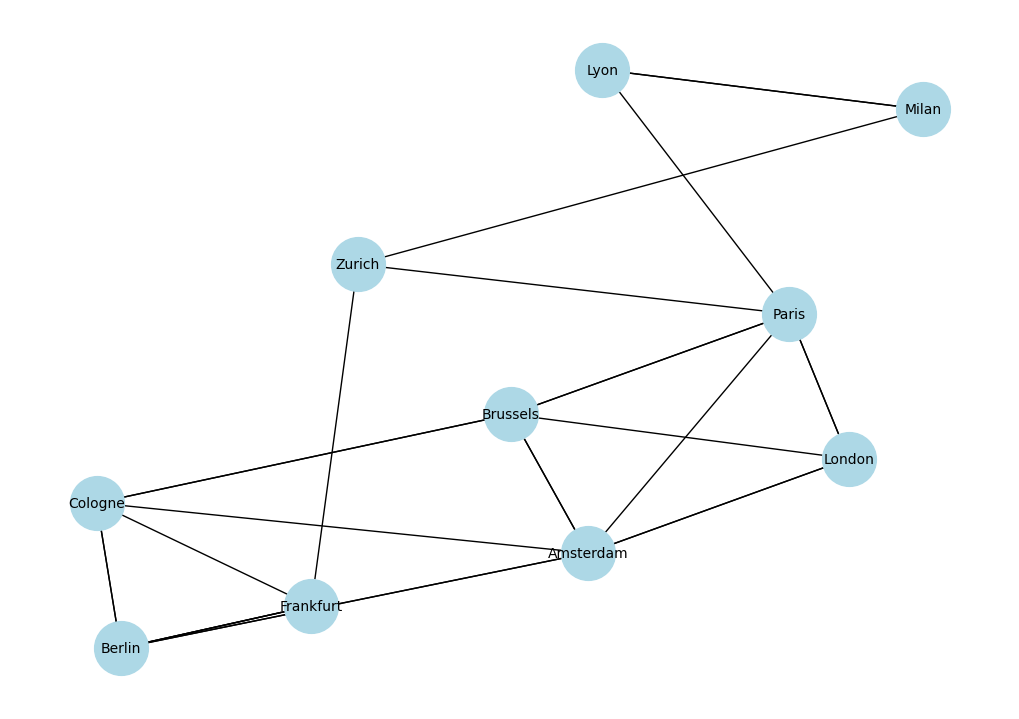

In [ ]:
# Create a layout for the graph
pos = nx.spring_layout(G, seed=7, k=1.5)

# Set figure size
plt.figure(figsize=(10, 7))

# Draw the network
nx.draw(
    G,
    pos,
    with_labels=True,
    node_size=1500,
    node_color="lightblue",
    font_size=10
)

plt.show()

In [12]:
def set_generalised_costs(G, lam):

    # Check that lambda is valid
    if lam < 0:
        raise ValueError("lambda must be non-negative")

    for _, _, _, data in G.edges(keys=True, data=True):

        price = data["price_gbp"]
        time = data["time_hours"]

        data["generalised_cost"] = price + lam * time

    return G

In [13]:
# Calculate generalised costs using lambda = £10/hour
set_generalised_costs(G, 10)

print("Generalised costs calculated successfully.")

Generalised costs calculated successfully.


In [ ]:
print(G["London"]["Paris"]["L01"]["generalised_cost"])

81.33


In [2]:
def dijkstra(G, start, destination):

    # initialises distance
    distances = {}
    for city in G.nodes():
        distances[city] = float("inf")

    distances[start] = 0
    # cities still to be processed
    unvisited = set(G.nodes())
    # store the previous city on the shortest path
    previous = {}

    while unvisited:

        current_city = None
        smallest_distance = float("inf")

        for city in unvisited:
            if distances[city] < smallest_distance:
                smallest_distance = distances[city]
                current_city = city

        # stop if no reachable city remains
        if current_city is None:
            break

        # stop if destination has been reached
        if current_city == destination:
            break

        # mark current city as visited
        unvisited.remove(current_city)

        # examine neigbouring cities
        for neighbour in G.neighbors(current_city):

            # only consider cities not visited
            if neighbour in unvisited:

                # examine each transport link between the cities
                for link_id, data in G[current_city][neighbour].items():

                    new_distance = distances[current_city] + data["generalised_cost"]

                    if new_distance < distances[neighbour]:
                        distances[neighbour] = new_distance
                        previous[neighbour] = (current_city, link_id)

    return distances, previous


In [14]:
distances, previous = dijkstra(G, "London", "Paris")

print("Shortest generalised cost:", distances["Paris"])
print("Previous link:", previous["Paris"])

Shortest generalised cost: 81.33
Previous link: ('London', 'L01')


In [17]:
# T09 - Create a small MultiGraph for testing

T = nx.MultiGraph()

# Add connections with generalised costs
T.add_edge("A", "B", key="AB", generalised_cost=4)
T.add_edge("A", "C", key="AC", generalised_cost=2)
T.add_edge("C", "B", key="CB", generalised_cost=1)
T.add_edge("B", "D", key="BD", generalised_cost=5)
T.add_edge("C", "D", key="CD", generalised_cost=8)

print("Test graph created.")
print("Nodes:", list(T.nodes()))
print("Edges:", list(T.edges(keys=True, data=True)))

Test graph created.
Nodes: ['A', 'B', 'C', 'D']
Edges: [('A', 'B', 'AB', {'generalised_cost': 4}), ('A', 'C', 'AC', {'generalised_cost': 2}), ('B', 'C', 'CB', {'generalised_cost': 1}), ('B', 'D', 'BD', {'generalised_cost': 5}), ('C', 'D', 'CD', {'generalised_cost': 8})]


In [18]:
# Running Dijkstra algorithm on the test graph

test_distances, test_previous = dijkstra(T, "A", "D")

print("Shortest cost:", test_distances["D"])
print("Previous node and link:", test_previous["D"])

Shortest cost: 8
Previous node and link: ('B', 'BD')


In [19]:
# Reconstruct the route from D back to A

route = ["D"]
current = "D"

while current != "A":
    current = test_previous[current][0]
    route.append(current)

route.reverse()

print("Shortest route:", " -> ".join(route))

Shortest route: A -> C -> B -> D


In [21]:
# T04 - London to Paris with lambda = 0

# Calculate costs using price only
set_generalised_costs(G, 0)

# Run Dijkstra
t04_distances, t04_previous = dijkstra(G, "London", "Paris")

# Display results
print("Lambda:", 0)
print("Shortest generalised cost:", t04_distances["Paris"])
print("Previous city and link:", t04_previous["Paris"])

# Reset graph costs to lambda = 10 for subsequent tests
set_generalised_costs(G, 10)

Lambda: 0
Shortest generalised cost: 28.49
Previous city and link: ('London', 'L16')
